In [60]:
import pandas as pd
import numpy as np
import ast 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression


file_directory = 'C:/Users/nphan/Desktop/UZH/uzh II/Advanced Machine Learning/'
df_MFCC = pd.read_csv(file_directory + 'MFCC_Full_Raw_20(nico).csv')
df_Metadata = pd.read_csv(file_directory + 'contextsvocs_groupproject_2026-04-09_104847.csv')

## Formating the MFCCs

the goals are : 
1. temporal summarization 
2. Compute mean and standard deviation for each coefficient 
3. Normalization 

matrix representation: 
- row : coefficient (represents the frequency band)
- column : time (chunks of 20-40milliseconds)
- cell value : magnitude/energy (volume)

In [61]:
# Compute mean and sd from raw MFCC
def extract_stats(mfcc_string):
    clean_str = mfcc_string.replace('[', '').replace(']', '').replace('\n', '')
    matrix = np.fromstring(clean_str, sep=',').reshape(20, -1)

    return np.concatenate([np.mean(matrix, axis=1), np.std(matrix, axis=1)])

# Table
X = pd.DataFrame(
    df_MFCC['mfccs'].apply(extract_stats).tolist(),
    index=df_MFCC['file_name']
)

X.columns = [f'mean_{i}' for i in range(20)] + [f'std_{i}' for i in range(20)]
X.index = X.index.str.replace('.wav', '', regex=False)
print("Features extracted. Shape:", X.shape)

# Get labels 
final_df = X.merge(
    df_Metadata[['audio_ID', 'context_label', 'child']], 
    left_index=True, 
    right_on='audio_ID'
)

# features vs. target 
y = final_df['context_label']
groups = final_df['child']
X_data = final_df.drop(columns=['audio_ID', 'context_label', 'child'])

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_data)

print(f"Merge successful! Final dataset has {X_scaled.shape[0]} rows.")

Features extracted. Shape: (1009, 40)
Merge successful! Final dataset has 1009 rows.


In [45]:
df_Metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1009 entries, 0 to 1008
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     1009 non-null   int64  
 1   audio_ID       1009 non-null   object 
 2   start_sec      1009 non-null   float64
 3   end_sec        1009 non-null   float64
 4   duration_sec   1009 non-null   float64
 5   child          1009 non-null   object 
 6   lang           1009 non-null   object 
 7   gender         1009 non-null   object 
 8   age            1009 non-null   int64  
 9   context_label  1009 non-null   object 
dtypes: float64(3), int64(2), object(5)
memory usage: 79.0+ KB


## Implementation of the Logisitic regression 

In [ ]:
import numpy as np
import pandas as pd
import random
import json
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

# --- 1. SETUP TEAM LOGIC & CONFIG ---

RANDOM_SEED = 42
SPLITS_DIR = Path("results/splits")
RESULTS_PATH = Path("results/baseline_results.json")
CLASS_NAMES = ['PLTOY', 'MOVE', 'INTER', 'EXTEV']

def determine_eval_protocol(df: pd.DataFrame) -> str:
    n = df["child"].nunique()
    if n >= 5:
        protocol = "holdout"
    elif n >= 3:
        protocol = "lopo"
    else:
        protocol = "kfold"
    print(f"Participants: {n}  →  Evaluation protocol: '{protocol}'")
    return protocol

def build_splits(df: pd.DataFrame, protocol: str, k_folds: int = 5, 
                 val_frac: float = 0.15, test_frac: float = 0.15) -> list:
    folds = []
    if "class4" not in df.columns:
        df["class4"] = df["context_label"]

    if protocol == "holdout":
        child_sizes = df.groupby("child").size().sort_values(ascending=False)
        children_by_size = child_sizes.index.tolist()
        n_test = max(1, round(len(children_by_size) * test_frac))
        n_val = max(1, round(len(children_by_size) * val_frac))
        
        test_ch = children_by_size[:n_test]
        val_ch = children_by_size[n_test:n_test + n_val]
        train_ch = children_by_size[n_test + n_val:]

        folds.append((df[df["child"].isin(train_ch)].copy(), 
                      df[df["child"].isin(val_ch)].copy(), 
                      df[df["child"].isin(test_ch)].copy()))

    elif protocol == "lopo":
        children = list(df["child"].unique())
        for i, test_child in enumerate(children):
            remaining = [c for c in children if c != test_child]
            val_child = remaining[i % len(remaining)]
            train_ch = [c for c in remaining if c != val_child]
            folds.append((df[df["child"].isin(train_ch)].copy(), 
                          df[df["child"] == val_child].copy(), 
                          df[df["child"] == test_child].copy()))
    else:
        from sklearn.model_selection import StratifiedKFold, train_test_split
        skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
        for trval_idx, test_idx in skf.split(df, df["class4"]):
            trval, test = df.iloc[trval_idx], df.iloc[test_idx]
            train, val = train_test_split(trval, test_size=val_frac, stratify=trval["class4"], random_state=RANDOM_SEED)
            folds.append((train.copy(), val.copy(), test.copy()))
    return folds

# --- 2. REPORTING FUNCTIONS  ---

def print_classification_report_team(preds, labels, split_name: str = ""):
    """Per-class classification report formatted to match the team style."""
    title = f"Classification Report — {split_name}" if split_name else "Classification Report"
    print(f"\n{'='*55}\n{title}\n{'='*55}")
    print(classification_report(labels, preds, target_names=None, digits=3, zero_division=0))

def save_results(results: dict, path: Path):
    """Save results as JSON, handling numpy types for compatibility."""
    path.parent.mkdir(parents=True, exist_ok=True)
    def _convert(obj):
        if isinstance(obj, (np.integer, np.floating)): return obj.item()
        if isinstance(obj, np.ndarray): return obj.tolist()
        return obj
    with open(path, "w") as f:
        json.dump(results, f, indent=2, default=_convert)
    print(f"\nResults saved → {path}")

# --- 3. EXECUTION PIPELINE ---

protocol = determine_eval_protocol(final_df)
official_folds = build_splits(final_df, protocol)

all_fold_results = []
best_c = 10 

print(f"\nStarting Evaluation Loop ({len(official_folds)} folds)...")

for i, (train_df, val_df, test_df) in enumerate(official_folds):
   
    features = [c for c in train_df.columns if c.startswith('mean_') or c.startswith('std_')]
    
    # Scale 
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features])
    X_test = scaler.transform(test_df[features])
    
    # Train
    model = LogisticRegression(C=best_c, max_iter=1000, solver='lbfgs', multi_class='multinomial')
    model.fit(X_train, train_df['context_label'])
    
    # Predict
    preds = model.predict(X_test)
    labels = test_df['context_label'].values
    
    # Metrics
    macro_f1 = f1_score(labels, preds, average='macro', zero_division=0)
    
    # Reporting per fold
    print_classification_report_team(preds, labels, split_name=f"Fold {i} (Test)")
    
    all_fold_results.append({
        "fold": i,
        "macro_f1": macro_f1,
        "predictions": preds,
        "actual_labels": labels
    })

# --- 4. FINAL AGGREGATION & STORAGE ---

mean_f1 = np.mean([f["macro_f1"] for f in all_fold_results])
std_f1 = np.std([f["macro_f1"] for f in all_fold_results])

final_metrics = {
    "protocol": protocol,
    "mean_macro_f1": mean_f1,
    "std_macro_f1": std_f1,
    "best_c": best_c,
    "model_type": "LogisticRegression_Baseline"
}

print("\n" + "="*30)
print("FINAL BASELINE SUMMARY")
print("="*30)
print(f"Macro-F1: {mean_f1:.4f} ± {std_f1:.4f}")
print("="*30)

save_results(final_metrics, RESULTS_PATH)

Participants: 9  →  Evaluation protocol: 'holdout'

Starting Evaluation Loop (1 folds)...

Classification Report — Fold 0 (Test)
              precision    recall  f1-score   support

       EXTEV      0.000     0.000     0.000        50
       INTER      0.293     0.975     0.450        79
        MOVE      0.000     0.000     0.000        47
       PLTOY      0.000     0.000     0.000        93

    accuracy                          0.286       269
   macro avg      0.073     0.244     0.113       269
weighted avg      0.086     0.286     0.132       269


FINAL BASELINE SUMMARY
Macro-F1: 0.1126 ± 0.0000

Results saved → results\baseline_results.json


c:\Users\nphan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\nphan\AppData\Local\Temp\ipykernel_49248\3670695491.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='F1', y='Class', data=f1_df, palette='magma', ax=axes[1])


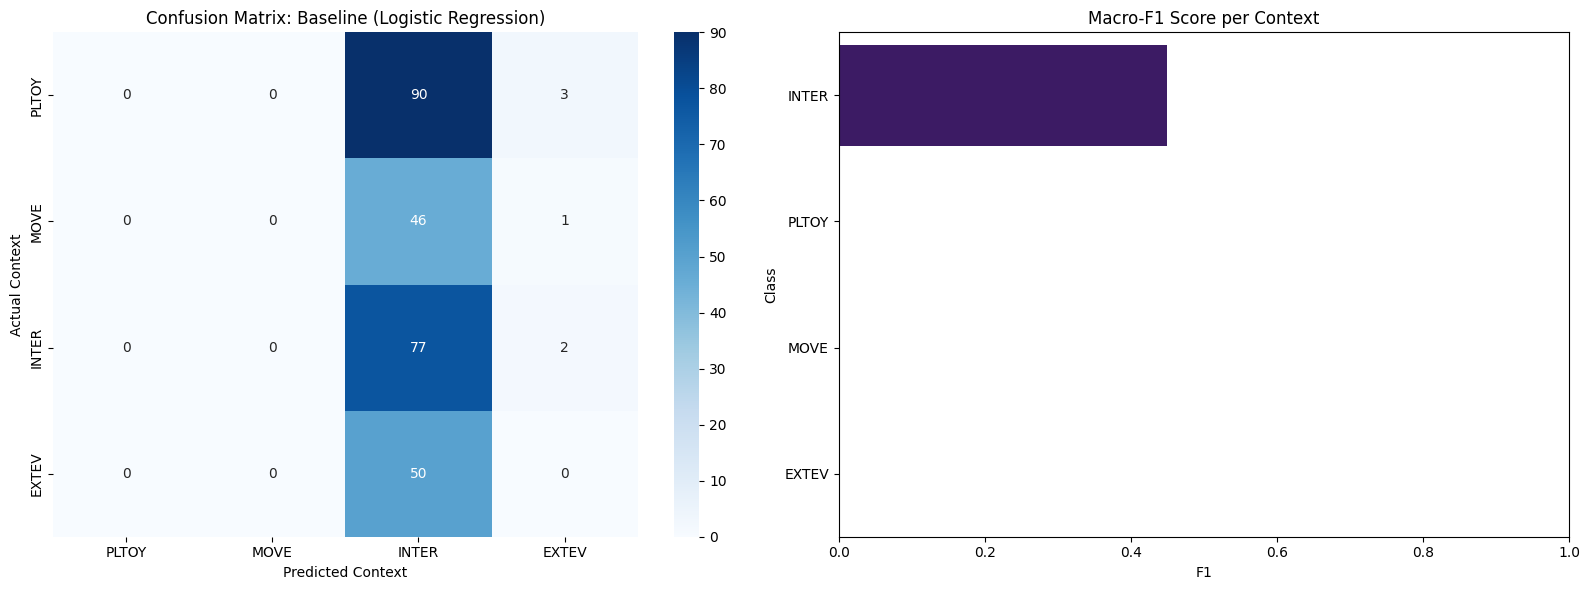

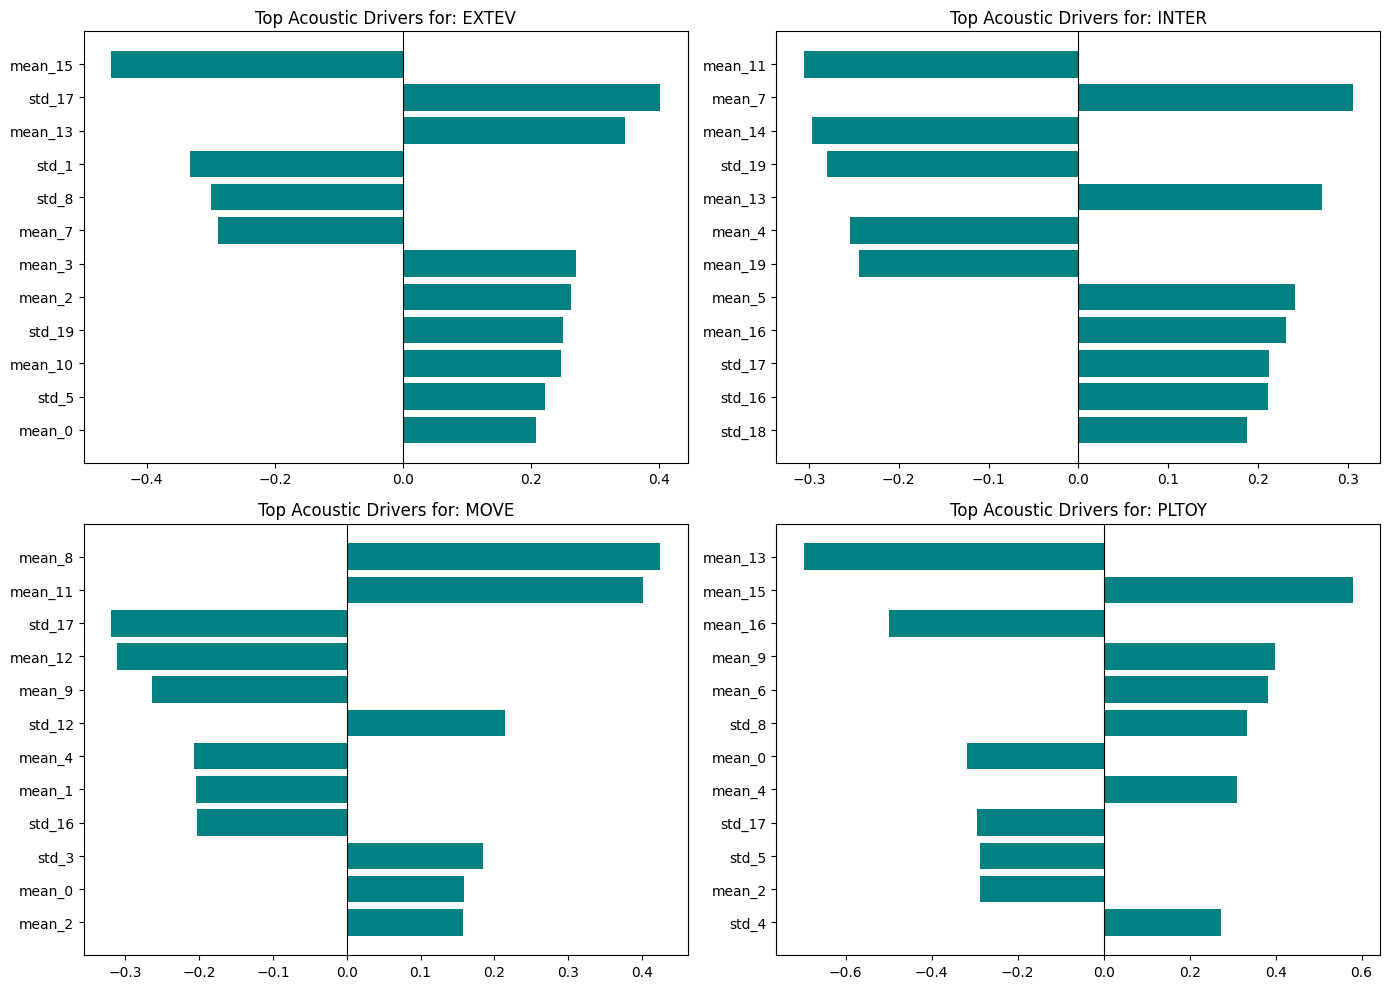

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_baseline_performance(all_fold_results, class_names, final_model, feature_names):
    """Generates figures to explain the baseline performance."""
    
    y_true = np.concatenate([f["actual_labels"] for f in all_fold_results])
    y_pred = np.concatenate([f["predictions"] for f in all_fold_results])
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # A) Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Confusion Matrix: Baseline (Logistic Regression)')
    axes[0].set_ylabel('Actual Context')
    axes[0].set_xlabel('Predicted Context')

    # B) Per-Class F1-Score
    from sklearn.metrics import f1_score
    per_class_f1 = f1_score(y_true, y_pred, average=None, labels=class_names)
    f1_df = pd.DataFrame({'Class': class_names, 'F1': per_class_f1}).sort_values('F1', ascending=False)
    
    sns.barplot(x='F1', y='Class', data=f1_df, palette='magma', ax=axes[1])
    axes[1].set_title('Macro-F1 Score per Context')
    axes[1].set_xlim(0, 1)

    plt.tight_layout()
    plt.show()

    # 3. Feature Importance (Why did the model choose what it chose?)
    plt.figure(figsize=(14, 10))
    for i, class_label in enumerate(final_model.classes_):
        coefs = final_model.coef_[i]
        top_idx = np.argsort(np.abs(coefs))[-12:]
        
        plt.subplot(2, 2, i+1)
        plt.barh(np.array(feature_names)[top_idx], coefs[top_idx], color='teal')
        plt.title(f"Top Acoustic Drivers for: {class_label}")
        plt.axvline(0, color='black', lw=0.8)

    plt.tight_layout()
    plt.show()

features_list = [c for c in X.columns if 'mean_' in c or 'std_' in c]
plot_baseline_performance(all_fold_results, CLASS_NAMES, model, features_list)